# NB02 — Q-learning training

**Question.** Can a small tabular Q-learning agent, seeing only the observation dict, learn a difficulty policy that differs usefully from the rule policy
in the simulator (growth + boredom-dropout ON)?

**Inputs.** `rl_core.env` (environment, rule policy), `rl_core.agent` (state buckets, reward, `QAgent`). No data files are read directly.
**Outputs.** `outputs/figures/02_*.png`, `outputs/tables/02_*.csv`, `outputs/models/q_main.json`, `q_no_strain.json`.

Training seeds are < 9,000,000; the quick check in step 6 uses seeds ≥ 9,000,000. Familiarization sessions use the rule; the agent acts from session W+1.

**Disclosure.** Literature-informed synthetic data — not clinical evidence. Simulation-only; not approved for use with children.

In [1]:
import sys, json, time
from pathlib import Path
T_NB = time.time()
RL_ROOT = Path.cwd().resolve().parent
for p in (RL_ROOT, RL_ROOT / "notebooks"):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))
import rlconfig as cfg
import rl_core
from rl_core import env as E
from rl_core.env import SimConfig, run_learner, sample_learner, rule_policy
from rl_core.agent import QAgent, AgentPolicy, state_of, reward, WEIGHTS

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from matplotlib.colors import ListedColormap
pd.set_option("display.width", 200, "display.max_columns", 40)
sns.set_theme(style="whitegrid")
for d in (cfg.FIGURES_DIR, cfg.TABLES_DIR, cfg.MODELS_DIR):
    d.mkdir(parents=True, exist_ok=True)
save_table = lambda df, n: df.to_csv(cfg.TABLES_DIR / f"02_{n}.csv", index=False)
def save_fig(fig, n): fig.savefig(cfg.FIGURES_DIR / f"02_{n}.png", dpi=130, bbox_inches="tight")
SIM = SimConfig(growth=True, boredom=True, eta=E.ETA)       # additions ON, everywhere in this notebook
LEARNERS = [sample_learner(100 + i) for i in range(100)]    # step 1-2 cohort (training-side seeds 100..199)
print(cfg.DISCLOSURE, "| eta =", E.ETA, "| DROP_A =", E.DROP_A, "DROP_C =", E.DROP_C)

Literature-informed synthetic data — not clinical evidence. Simulation-only; not approved for use with children. | eta = 0.04 | DROP_A = -5.2 DROP_C = 1.0


## 1. Choose tau from the simulator

For each fixed level L = 1..5 ("hold at level L": step towards L whenever safety allows, then hold), 100 learners × 10 sessions, additions ON.
tau = the first-try success at the level with the **highest mastery gain**, rounded to 0.05. This replaces the Blueprint §7B target band (0.70–0.85),
which the simulator cannot reach in a way that also helps learning — a documented deviation.

In [2]:
def hold_at(L):
    def pol(obs, allowed, env):
        d = obs["difficulty"]
        if d > L and "decrease_difficulty" in allowed: return "decrease_difficulty"
        if d < L and "increase_difficulty" in allowed: return "increase_difficulty"
        return "hold"
    return pol

def cohort(policy, learners, seed0, n_sessions=10, sim=SIM):
    ds, ss = [], []
    for i, L in enumerate(learners):
        d, s = run_learner(policy, L, n_sessions=n_sessions, seed=seed0 + i, sim=sim)
        ds.append(d.assign(learner=i)); ss.append(s.assign(learner=i))
    return pd.concat(ds, ignore_index=True), pd.concat(ss, ignore_index=True)

def per_learner(S):
    g = S.groupby("learner")
    return pd.DataFrame({"mastery_gain": g.apply(lambda x: x.mastery_end.iloc[-1] - x.mastery_start.iloc[0], include_groups=False),
                         "first_try": g.first_try_rate.mean(), "mean_difficulty": g.mean_difficulty.mean(),
                         "dropout": g.dropout.mean(), "safety_events": g.safety_override_count.mean()})
pm = lambda x: f"{x.mean():.4f} ± {x.std() / np.sqrt(len(x)):.4f}"

rows = []
for L in range(1, 6):
    _, S = cohort(hold_at(L), LEARNERS, 100)
    P = per_learner(S)
    rows.append({"level": L, **{c: pm(P[c]) for c in P.columns}, "_gain": P.mastery_gain.mean(), "_ft": P.first_try.mean()})
LV = pd.DataFrame(rows)
best = LV.loc[LV._gain.idxmax()]
TAU = round(best._ft * 20) / 20
display(LV.drop(columns=["_gain", "_ft"]).set_index("level")); save_table(LV.drop(columns=["_gain", "_ft"]), "tau_by_level")
print(f"best level = {int(best.level)} (mastery gain {best._gain:.4f}), first-try there = {best._ft:.4f}  ->  tau = {TAU}")

C:\Users\Yasindu\AppData\Local\Temp\ipykernel_28376\1631900113.py:14: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  return pd.concat(ds, ignore_index=True), pd.concat(ss, ignore_index=True)


C:\Users\Yasindu\AppData\Local\Temp\ipykernel_28376\1631900113.py:14: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  return pd.concat(ds, ignore_index=True), pd.concat(ss, ignore_index=True)


C:\Users\Yasindu\AppData\Local\Temp\ipykernel_28376\1631900113.py:14: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  return pd.concat(ds, ignore_index=True), pd.concat(ss, ignore_index=True)


,mastery_gain,first_try,mean_difficulty,dropout,safety_events
level,,,,,
1,0.0560 ± 0.0023,0.7026 ± 0.0093,1.2666 ± 0.0097,0.2630 ± 0.0161,0.0790 ± 0.0190
2,0.1168 ± 0.0047,0.7186 ± 0.0088,1.9420 ± 0.0084,0.1670 ± 0.0164,0.0940 ± 0.0188
3,0.1497 ± 0.0043,0.6912 ± 0.0105,2.2925 ± 0.0255,0.1280 ± 0.0122,0.1570 ± 0.0270
4,0.1172 ± 0.0025,0.6435 ± 0.0098,2.4551 ± 0.0432,0.1240 ± 0.0121,0.3890 ± 0.0499
5,0.0998 ± 0.0038,0.6203 ± 0.0086,2.4994 ± 0.0467,0.1350 ± 0.0128,0.6890 ± 0.0652


best level = 3 (mastery gain 0.1497), first-try there = 0.6912  ->  tau = 0.7


### Findings — step 1

100 learners × 10 sessions per fixed level, additions ON, mean ± SE:

| level | mastery gain | first-try | mean difficulty reached | dropout / session | safety events / session |
|---|---|---|---|---|---|
| 1 | 0.0560 ± 0.0023 | 0.703 | 1.27 | 0.263 | 0.079 |
| 2 | 0.1168 ± 0.0047 | 0.719 | 1.94 | 0.167 | 0.094 |
| **3** | **0.1497 ± 0.0043** | **0.691** | 2.29 | 0.128 | 0.157 |
| 4 | 0.1172 ± 0.0025 | 0.644 | 2.46 | 0.124 | 0.389 |
| 5 | 0.0998 ± 0.0038 | 0.620 | 2.50 | 0.135 | 0.689 |

- Mastery gain peaks at **level 3** (0.150); first-try success there is 0.691, so **tau = 0.70**. Gain falls on both sides (too easy: boredom dropout, little stretch; too hard: more errors and safety events). Levels 4–5 cannot be held: safety pushes the learner down, so the mean reached is only ~2.5.
- **Documented deviation from Blueprint §7B:** tau is derived from the simulator, not taken from the 0.70–0.85 target band. The value lands at the band's lower edge, but it is not claimed to be clinically meaningful.

## 2. Dropout + variety check

Rule policy, additions ON, 100 learners × 10 sessions, for several values of DROP_A (dropout = sigmoid(DROP_A + 0.6·boredom_run + 1.0·strain)).
Early-end rate = share of sessions that end by dropout. Target ≈ 15 %. Then the spread of starting mastery.

In [3]:
rows = []
for a in (-6.0, -5.5, -5.4, -5.2, -5.0, -4.5, -4.0):
    E.DROP_A = a
    _, S = cohort(rule_policy, LEARNERS, 100)
    rows.append(dict(DROP_A=a, early_end_rate=S.dropout.mean(), learners_with_a_dropout=S.groupby("learner").dropout.max().mean(),
                     tasks_per_session=S.tasks.mean(), mastery_gain=per_learner(S).mastery_gain.mean()))
DA = pd.DataFrame(rows)
chosen = float(DA.loc[(DA.early_end_rate - 0.15).abs().idxmin(), "DROP_A"])
E.DROP_A = chosen
display(DA.round(4)); save_table(DA, "drop_a_table")
print("chosen DROP_A =", chosen)
assert chosen == -5.2, "update DROP_A in rl_core/env.py to the chosen value"

,DROP_A,early_end_rate,learners_with_a_dropout,tasks_per_session,mastery_gain
0,-6.0,0.073,0.45,11.660,0.1147
1,-5.5,0.114,0.61,11.452,0.1136
2,-5.4,0.125,0.66,11.407,0.1133
3,-5.2,0.145,0.73,11.282,0.1126
4,-5.0,0.173,0.80,11.133,0.1125
5,-4.5,0.235,0.92,10.758,0.1108
6,-4.0,0.332,0.98,10.203,0.1069


chosen DROP_A = -5.2


mean-7 starting mastery: min 0.156  q10 0.187  median 0.280  q90 0.400  max 0.512  sd 0.080
share < 0.25: 0.373   0.25-0.5: 0.625   >= 0.5: 0.002 | grades: {2: 1048, 3: 952}


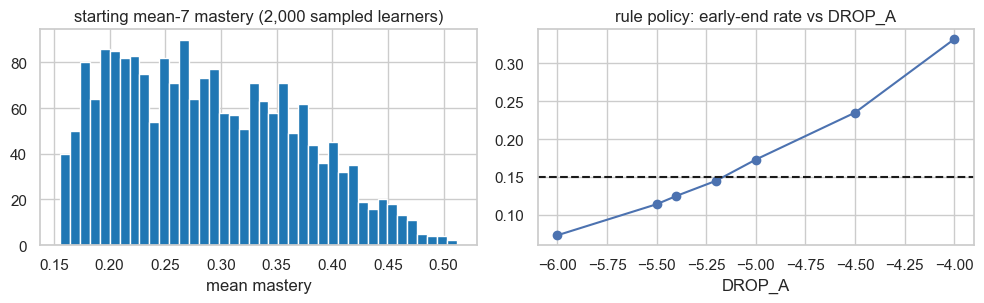

In [4]:
starts = [sample_learner(100 + i) for i in range(2000)]
m7 = np.array([np.mean(list(L["mastery"].values())) for L in starts])
grades = pd.Series([L["grade"] for L in starts]).value_counts().sort_index()
print("mean-7 starting mastery: min %.3f  q10 %.3f  median %.3f  q90 %.3f  max %.3f  sd %.3f" % (m7.min(), *np.quantile(m7, [.1, .5, .9]), m7.max(), m7.std()))
print("share < 0.25: %.3f   0.25-0.5: %.3f   >= 0.5: %.3f" % ((m7 < .25).mean(), ((m7 >= .25) & (m7 < .5)).mean(), (m7 >= .5).mean()), "| grades:", grades.to_dict())
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].hist(m7, bins=40, color="tab:blue"); ax[0].set_title("starting mean-7 mastery (2,000 sampled learners)"); ax[0].set_xlabel("mean mastery")
ax[1].plot(DA.DROP_A, DA.early_end_rate, "o-"); ax[1].axhline(.15, color="k", ls="--")
ax[1].set_title("rule policy: early-end rate vs DROP_A"); ax[1].set_xlabel("DROP_A")
fig.tight_layout(); save_fig(fig, "start_mastery_and_dropout"); plt.show()

### Findings — step 2

- **DROP_A = −5.2** (dropout = sigmoid(−5.2 + 0.6·boredom_run + 1.0·strain)). Rule policy, 100 learners × 10 sessions: early-end rate **14.5 %** of sessions (73 % of learners have at least one early end). Table: −6.0 → 7.3 %, −5.5 → 11.4 %, −5.4 → 12.5 %, **−5.2 → 14.5 %**, −5.0 → 17.3 %, −4.5 → 23.5 %, −4.0 → 33.2 %. The old value (−4.0 with the strain coefficient 2.0) gave 36.7 % in NB01.
- **Starting mastery** (2,000 sampled learners, random session 1–25): mean-7 **min 0.156, q10 0.187, median 0.280, q90 0.400, max 0.512**, sd 0.080 (NB01's session-1-only profile spanned 0.156–0.189). 37 % start below 0.25, 62 % between 0.25 and 0.5, 0.2 % above 0.5; grades 2 / 3 = 1,048 / 952. The spread is real but still tops out near 0.5: the dataset has no advanced learners within 25 sessions.
- Code note: dropout is not applied after a task nobody attempted (a technical pause on task 1 followed by dropout gave a zero-length session that crashed the aggregation).

## 3. Train Q-learning (combined mode, additions ON)

State = difficulty × first-try bucket × strain bucket × mastery bucket (135). Reward = 0.5·fit + 0.3·completed − 0.4·strain − 1.0·safety − 1.0·dropout.
epsilon 0.10, alpha 0.10, gamma 0.90; the agent holds for the first 3 tasks of a session. One shared agent learns online across learners,
25 sessions per learner. Time a 50-learner run first, then choose the number of learners.

In [5]:
TRAIN_SEED0 = 1000        # training seeds 1000.. (< 9,000,000)
SESSIONS = 25

def train(w, n, seed0=TRAIN_SEED0, log_every=500):
    agent = QAgent(); pol = AgentPolicy(agent, TAU, w, seed=seed0)
    rows, t0 = [], time.time()
    for i in range(n):
        seed = seed0 + i
        pol.rewards.clear()
        d, s = run_learner(pol, sample_learner(seed), n_sessions=SESSIONS, seed=seed, sim=SIM)
        a = d[(d.phase != "familiarization") & (d.tasks_done >= agent.min_tasks)]
        c = a.action.value_counts()
        rows.append(dict(learner=i, reward_sum=float(np.sum(pol.rewards)), n_dec=len(pol.rewards), **{k: int(c.get(k, 0)) for k in E.ACTIONS},
                         mean_difficulty=a.difficulty.mean(), states_visited=len(agent.visits), dropout=s.dropout.mean(),
                         safety_events=s.safety_override_count.mean()))
        if log_every and (i + 1) % log_every == 0:
            print(f"  {i + 1}/{n} learners  {time.time() - t0:.0f}s  states visited {len(agent.visits)}/135", flush=True)
    return agent, pd.DataFrame(rows), time.time() - t0

_, _, t50 = train(WEIGHTS, 50, log_every=0)
print(f"50 learners x {SESSIONS} sessions: {t50:.1f}s  ({t50 / 50:.3f}s per learner)")
N_TRAIN = 3000
print(f"N_TRAIN = {N_TRAIN} learners -> projected {N_TRAIN * t50 / 50 / 60:.1f} min per run (two runs: main + no-strain ablation)")

50 learners x 25 sessions: 15.2s  (0.303s per learner)
N_TRAIN = 3000 learners -> projected 15.2 min per run (two runs: main + no-strain ablation)


  500/3000 learners  152s  states visited 101/135


  1000/3000 learners  326s  states visited 110/135


  1500/3000 learners  482s  states visited 112/135


  2000/3000 learners  628s  states visited 116/135


  2500/3000 learners  772s  states visited 118/135


  3000/3000 learners  908s  states visited 122/135


main run: 15.1 min, 611,387 learning decisions


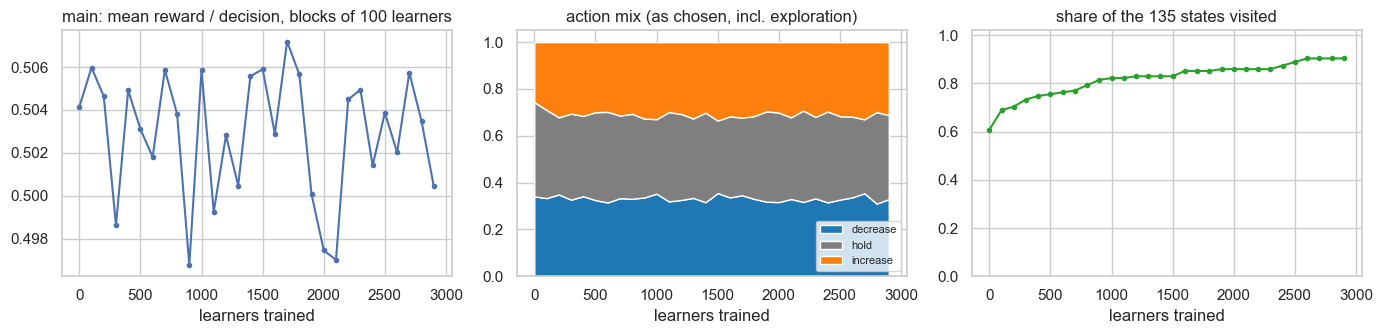

mean reward: first 6 blocks 0.5036 | middle 0.5041 | last 6 blocks 0.5028; slope over last 40% of blocks = +0.00018 per block
states visited at end: 122/135 (90.4%); never visited: 13
final-5-block action mix: {'decrease_difficulty': 0.332, 'hold': 0.354, 'increase_difficulty': 0.315}


In [6]:
agent_main, TR_main, t_main = train(WEIGHTS, N_TRAIN)
print(f"main run: {t_main / 60:.1f} min, {TR_main.n_dec.sum():,} learning decisions")
BLOCK = N_TRAIN // 30
def blocks(TR):
    b = TR.groupby(TR.learner // BLOCK)
    out = pd.DataFrame({"reward": b.reward_sum.sum() / b.n_dec.sum(), "states_share": b.states_visited.max() / 135,
                        "mean_difficulty": b.mean_difficulty.mean(), "dropout": b.dropout.mean(), "safety_events": b.safety_events.mean()})
    tot = b[list(E.ACTIONS)].sum().sum(axis=1)
    for k in E.ACTIONS:
        out[k] = b[k].sum() / tot
    return out
B_main = blocks(TR_main)

def plot_training(B, name, title):
    fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
    ax[0].plot(B.index * BLOCK, B.reward, "o-", ms=3); ax[0].set_title(f"{title}: mean reward / decision, blocks of {BLOCK} learners")
    ax[0].set_xlabel("learners trained")
    ax[1].stackplot(B.index * BLOCK, [B[k] for k in E.ACTIONS], labels=["decrease", "hold", "increase"], colors=["tab:blue", "tab:gray", "tab:orange"])
    ax[1].set_title("action mix (as chosen, incl. exploration)"); ax[1].legend(loc="lower right", fontsize=8); ax[1].set_xlabel("learners trained")
    ax[2].plot(B.index * BLOCK, B.states_share, "o-", ms=3, color="tab:green"); ax[2].set_ylim(0, 1.02); ax[2].set_title("share of the 135 states visited")
    ax[2].set_xlabel("learners trained")
    fig.tight_layout(); save_fig(fig, name); plt.show()
plot_training(B_main, "training_main", "main")
save_table(B_main.reset_index(), "training_blocks_main")

q = len(B_main) // 5
seg = lambda a, b: B_main.reward.iloc[a:b].mean()
slope = np.polyfit(np.arange(len(B_main) - 2 * q, len(B_main)), B_main.reward.iloc[-2 * q:], 1)[0]
print(f"mean reward: first {q} blocks {seg(0, q):.4f} | middle {seg(2 * q, 3 * q):.4f} | last {q} blocks {seg(-q, None):.4f}; slope over last 40% of blocks = {slope:+.5f} per block")
print(f"states visited at end: {len(agent_main.visits)}/135 ({len(agent_main.visits) / 135:.1%}); never visited: {135 - len(agent_main.visits)}")
print("final-5-block action mix:", B_main[list(E.ACTIONS)].iloc[-5:].mean().round(3).to_dict())

### Findings — step 3

- **Timing:** 50 learners × 25 sessions = 15.2 s (0.30 s/learner). **N_TRAIN = 3,000 learners** (seeds 1000–3999; 75,000 sessions; 611,387 learning decisions) took **15.1 min**; the ablation run took 16.0 min, so both fit in ≈ 31 min.
- **No visible learning curve — a flat plateau from the first block.** Mean reward per decision: first 6 blocks (of 100 learners) 0.5036, middle 0.5041, last 6 blocks 0.5028; slope over the last 40 % of blocks +0.0002 per block. Q-values do move (they reach 2–3, close to the r/(1−γ) scale), but the *policy's reward* does not change measurably with training in this setup. Likely reasons: the safety controller overrides a large share of actions, so the choice rarely changes the next task; and the early learning happens within the first few hundred learners, faster than a 100-learner block resolves.
- **Action mix** barely moves: final 5 blocks 33.2 % decrease / 35.4 % hold / 31.5 % increase (including 10 % exploration). The agent does not collapse to one action.
- **State coverage:** 122 of 135 states visited (90.4 %); 101 after 500 learners, 110 after 1,000, 118 after 2,500. The 13 unvisited states are rare corners: 8 are high strain with high mastery (levels 1-4), the rest are level 5 with low first-try or low strain with high first-try.

## 4. Ablation: strain weight = 0

Identical training (same learners, seeds, agent settings) with `w_strain = 0`. This is the frustration experiment; it is evaluated in NB03.

  500/3000 learners  154s  states visited 96/135


  1000/3000 learners  313s  states visited 108/135


  1500/3000 learners  471s  states visited 113/135


  2000/3000 learners  633s  states visited 119/135


  2500/3000 learners  804s  states visited 124/135


  3000/3000 learners  960s  states visited 125/135


no-strain run: 16.0 min


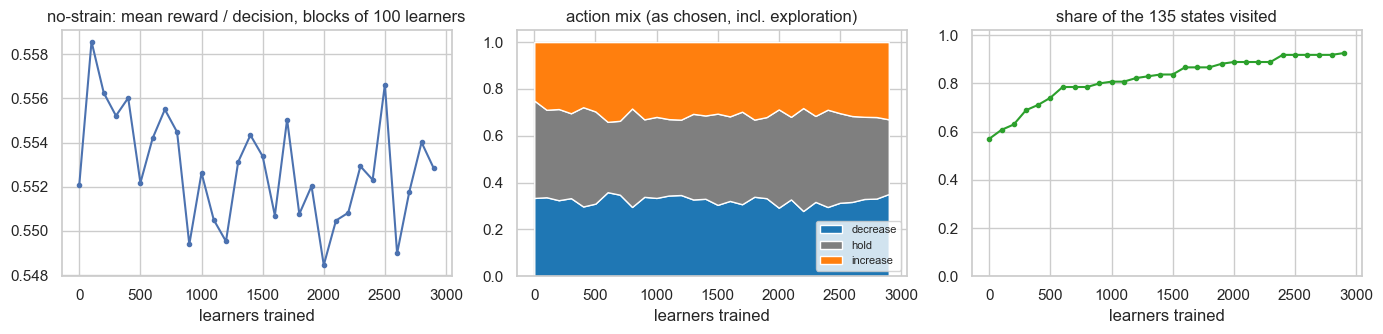

,states_share,mean_difficulty,dropout,safety_events,decrease_difficulty,hold,increase_difficulty
main,0.9007,2.4093,0.1770,0.0626,0.3316,0.3535,0.3149
no_strain,0.9200,2.4424,0.1786,0.0615,0.3288,0.3536,0.3176


In [7]:
W_NS = {**WEIGHTS, "strain": 0.0}
agent_ns, TR_ns, t_ns = train(W_NS, N_TRAIN)
print(f"no-strain run: {t_ns / 60:.1f} min")
B_ns = blocks(TR_ns)
plot_training(B_ns, "training_no_strain", "no-strain")
save_table(B_ns.reset_index(), "training_blocks_no_strain")
last = lambda B: B.iloc[-5:].mean()
cmp_ = pd.DataFrame({"main": last(B_main), "no_strain": last(B_ns)}).T.drop(columns=["reward"])
display(cmp_.round(4)); save_table(cmp_.reset_index(), "ablation_last5_blocks")

### Findings — step 4

- Ablation (strain weight 0, same 3,000 learners and seeds, 16.0 min): it ends up **almost the same as the main run** — last-5-block action mix 32.9 / 35.4 / 31.8 % (main 33.2 / 35.4 / 31.5), mean difficulty chosen 2.44 vs 2.41, dropout per session 0.179 vs 0.177, safety events 0.062 vs 0.063, states visited 125 vs 122.
- So at the training level the strain penalty has no visible effect: the strain term (0.4 × strain, strain is mostly < 0.3) is small next to the other terms, and the safety / dropout terms already penalise high strain. Whether frustration differs is tested on new learners in NB03; this note is only about the training statistics. Both models are saved.

## 5. What it learned

Greedy action of the main agent over difficulty × first-try bucket, one panel per strain bucket, mastery = mid, next to the rule's most common choice
for the same cells (rule decisions from 200 other learners × 25 sessions, additions ON; the rule's raw proposal, before safety). Blank = cell not visited
by Q (top) or fewer than 10 rule decisions (bottom).

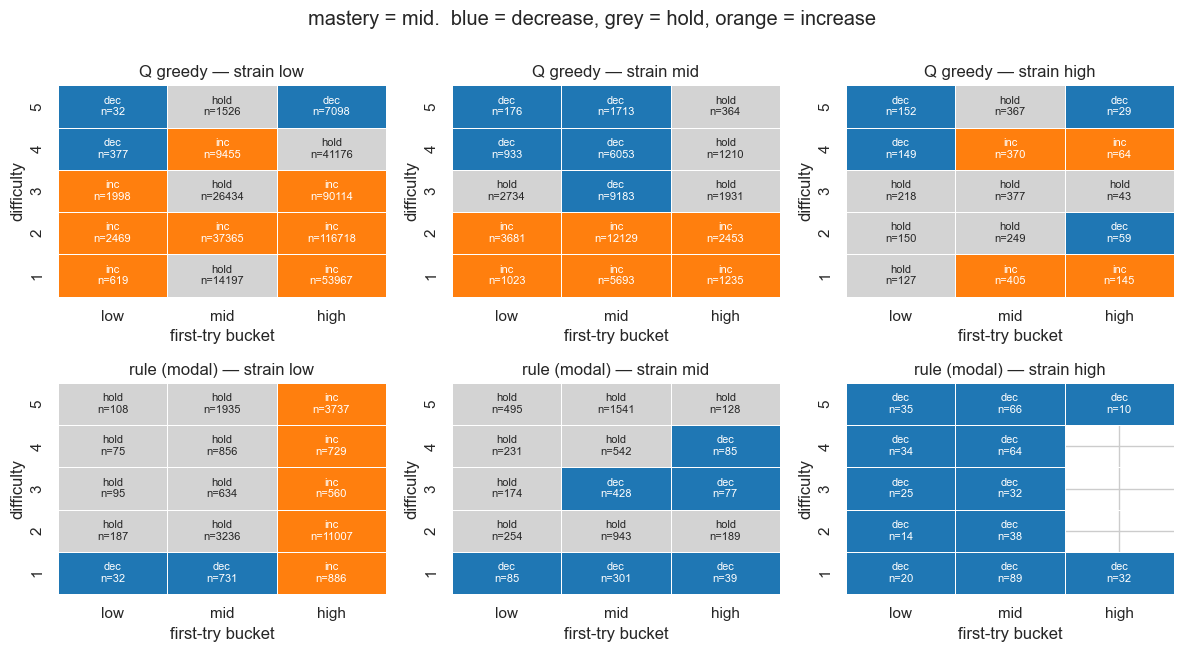

In [8]:
RULE_LEARNERS = [sample_learner(20_000 + i) for i in range(200)]
Dr, _ = cohort(rule_policy, RULE_LEARNERS, 20_000, n_sessions=25)
Dr = Dr[(Dr.phase != "familiarization") & (Dr.tasks_done >= 3)].copy()
Dr["s"] = [state_of(r) for r in Dr[["difficulty", "first_try", "strain", "mastery", "tasks_done"]].to_dict("records")]
code_of = {a: i - 1 for i, a in enumerate(E.ACTIONS)}
short = {-1: "dec", 0: "hold", 1: "inc"}
rule_mode = {s: (g.action.mode().iloc[0], len(g), g.action.value_counts(normalize=True).max()) for s, g in Dr.groupby("s")}
agent_g = agent_main.greedy()
FT, ST, MD = ["low", "mid", "high"], ["low", "mid", "high"], 1
cmap = ListedColormap(["tab:blue", "lightgray", "tab:orange"])
fig, ax = plt.subplots(2, 3, figsize=(12, 6.5))
for sb in range(3):
    gq = np.full((5, 3), np.nan); gr = np.full((5, 3), np.nan)
    tq, tr = np.full((5, 3), "", dtype=object), np.full((5, 3), "", dtype=object)
    for d in range(1, 6):
        for fb in range(3):
            s = (d, fb, sb, MD)
            if agent_main.visits.get(s, 0) > 0:
                a = agent_g._best(s, list(E.ACTIONS)); gq[d - 1, fb] = code_of[a]; tq[d - 1, fb] = short[code_of[a]] + f"\nn={agent_main.visits[s]}"
            if s in rule_mode and rule_mode[s][1] >= 10:
                a = rule_mode[s][0]; gr[d - 1, fb] = code_of[a]; tr[d - 1, fb] = short[code_of[a]] + f"\nn={rule_mode[s][1]}"
    for row, (g, t, nm) in enumerate([(gq, tq, "Q greedy"), (gr, tr, "rule (modal)")]):
        sns.heatmap(np.ma.masked_invalid(g), ax=ax[row, sb], cmap=cmap, vmin=-1, vmax=1, cbar=False, annot=t, fmt="", annot_kws={"fontsize": 8},
                    xticklabels=FT, yticklabels=range(1, 6), linewidths=.5, linecolor="white")
        ax[row, sb].set_title(f"{nm} — strain {ST[sb]}"); ax[row, sb].set_xlabel("first-try bucket"); ax[row, sb].set_ylabel("difficulty")
        ax[row, sb].invert_yaxis()
fig.suptitle("mastery = mid.  blue = decrease, grey = hold, orange = increase", y=1.0)
fig.tight_layout(); save_fig(fig, "q_vs_rule_heatmap"); plt.show()

In [9]:
rows = []
for s, qv in agent_main.Q.items():
    if s in rule_mode and rule_mode[s][1] >= 10 and agent_main.visits.get(s, 0) >= 20:
        rows.append(dict(state=s, q_visits=agent_main.visits[s], q_dec=qv[0], q_hold=qv[1], q_inc=qv[2], q_greedy=agent_g._best(s, list(E.ACTIONS)),
                         rule_modal=rule_mode[s][0], rule_n=rule_mode[s][1], rule_modal_share=rule_mode[s][2]))
CMP = pd.DataFrame(rows)
CMP["agree"] = CMP.q_greedy == CMP.rule_modal
w = CMP.q_visits
print(f"cells with >=20 Q visits and >=10 rule decisions: {len(CMP)}; greedy Q = rule's modal action in {CMP.agree.mean():.1%} of them ({(w * CMP.agree).sum() / w.sum():.1%} weighted by Q visits)")
print("Q greedy mix over these cells:", CMP.q_greedy.value_counts().to_dict(), "| rule modal mix:", CMP.rule_modal.value_counts().to_dict())
CMP["state"] = CMP.state.astype(str)
save_table(CMP.sort_values("q_visits", ascending=False), "q_vs_rule_cells")
CMP["difficulty"] = CMP.state.str[1].astype(int)
g = CMP.groupby("difficulty")
print("by difficulty: number of cells where Q / rule choose each action")
display(pd.concat({"Q": g.q_greedy.value_counts().unstack(fill_value=0), "rule": g.rule_modal.value_counts().unstack(fill_value=0)}, axis=1))
display(CMP[~CMP.agree].sort_values("q_visits", ascending=False).head(12).round(3))

cells with >=20 Q visits and >=10 rule decisions: 73; greedy Q = rule's modal action in 24.7% of them (59.3% weighted by Q visits)
Q greedy mix over these cells: {'increase_difficulty': 27, 'decrease_difficulty': 25, 'hold': 21} | rule modal mix: {'decrease_difficulty': 33, 'hold': 29, 'increase_difficulty': 11}
by difficulty: number of cells where Q / rule choose each action


Q                                         rule                         
q_greedy   decrease_difficulty hold increase_difficulty decrease_difficulty hold increase_difficulty
difficulty                                                                                          
1                            0    2                  15                  15    0                   2
2                            2    7                   8                   4   10                   3
3                            8    6                   2                   7    7                   2
4                            8    2                   2                   4    6                   2
5                            7    4                   0                   3    6                   2

,state,q_visits,q_dec,q_hold,q_inc,q_greedy,rule_modal,rule_n,rule_modal_share,agree,difficulty
33,"(4, 2, 0, 1)",41176,2.163,3.042,2.376,hold,increase_difficulty,729,0.774,False,4
15,"(2, 1, 0, 1)",37365,2.108,2.409,2.902,increase_difficulty,hold,3236,0.805,False,2
5,"(2, 2, 0, 0)",31041,2.180,2.596,2.217,hold,increase_difficulty,2169,0.892,False,2
14,"(1, 1, 0, 1)",14197,0.000,2.755,2.039,hold,decrease_difficulty,731,0.668,False,1
26,"(2, 1, 1, 1)",12129,1.814,2.119,3.071,increase_difficulty,hold,943,0.857,False,2
2,"(1, 1, 0, 0)",11244,0.000,1.789,2.824,increase_difficulty,decrease_difficulty,562,0.637,False,1
8,"(2, 1, 1, 0)",11203,2.356,2.041,2.221,decrease_difficulty,hold,747,0.817,False,2
29,"(4, 1, 0, 1)",9455,2.187,2.319,2.776,increase_difficulty,hold,856,0.868,False,4
50,"(5, 2, 0, 1)",7098,2.658,2.041,0.000,decrease_difficulty,increase_difficulty,3737,0.891,False,5
3,"(1, 1, 1, 0)",6633,0.000,1.115,2.398,increase_difficulty,decrease_difficulty,454,0.736,False,1


### Findings — step 5

Rule decisions from 200 other learners × 25 sessions (additions ON), cells with ≥ 20 Q visits and ≥ 10 rule decisions (73 cells):

- **Agreement is low: greedy Q equals the rule's most common action in 24.7 % of cells** (59.3 % weighted by how often Q visited them, because the busy cells are the easy ones to agree on).
- **At the bottom (level 1–2) Q wants to go up**: at level 1, Q increases in 15 of 17 cells and holds in 2; the rule's modal action there is *decrease* in 15 cells, which is a no-op at level 1. At level 2 Q mostly increases (8) or holds (7); the rule mostly holds (10).
- **At the top (level 4–5) Q pulls down**: at level 4 it decreases in 8 of 12 cells and at level 5 in 7 of 11, while the rule's modal action is mostly hold or increase (e.g. level 5, high first-try, low strain: rule increase, Q decrease). So Q concentrates difficulty around levels 2–3, which is the level that gave the best mastery gain in step 1.
- Q is also more willing to **hold at level 4 when first-try is high and strain is low** where the rule increases, and to **increase at level 2 with mid first-try** where the rule holds.
- Caveat: Q-values in neighbouring cells differ by small amounts (e.g. 2.41 vs 2.90), and the training curve was flat, so individual cells are noisy; the pattern above (up from the bottom, down from the top) is the consistent part.

## 6. Quick check — greedy Q vs rule on 100 new learners

Seeds ≥ 9,000,000, 10 sessions, additions ON. Mean reward is per decision (decisions from the 4th task of a mastery-driven session on, the same for both policies),
scored with the main weights and tau. This is a quick check, not the full evaluation (NB03).

In [10]:
class RuleScored(AgentPolicy):
    def __call__(self, obs, allowed, env): return env.rule_action()

EVAL = [sample_learner(9_000_000 + i) for i in range(100)]
def evaluate(make):
    rows = []
    for i, L in enumerate(EVAL):
        pol = make(i)
        _, s = run_learner(pol, L, n_sessions=10, seed=9_000_000 + i, sim=SIM)
        rows.append(dict(reward=np.mean(pol.rewards) if pol.rewards else np.nan, mastery_gain=s.mastery_end.iloc[-1] - s.mastery_start.iloc[0],
                         dropout=s.dropout.mean(), safety_events=s.safety_override_count.mean(), first_try=s.first_try_rate.mean(),
                         mean_difficulty=s.mean_difficulty.mean()))
    return pd.DataFrame(rows)
Q_ev = evaluate(lambda i: AgentPolicy(agent_main.greedy(), TAU, WEIGHTS, seed=i, learn=False))
R_ev = evaluate(lambda i: RuleScored(QAgent(), TAU, WEIGHTS, seed=i, learn=False))
QC = pd.DataFrame({"rule": R_ev.apply(pm), "greedy Q": Q_ev.apply(pm)}).T
dif = Q_ev - R_ev
QC.loc["Q - rule (paired)"] = [f"{dif[c].mean():+.4f} ± {dif[c].std() / np.sqrt(dif[c].count()):.4f}" for c in QC.columns]
display(QC); save_table(QC.reset_index().rename(columns={"index": "policy"}), "quick_check")

,reward,mastery_gain,dropout,safety_events,first_try,mean_difficulty
rule,0.4315 ± 0.0077,0.1160 ± 0.0031,0.1480 ± 0.0117,0.2700 ± 0.0369,0.6579 ± 0.0084,2.1666 ± 0.0401
greedy Q,0.4711 ± 0.0051,0.1329 ± 0.0028,0.1340 ± 0.0112,0.1460 ± 0.0250,0.6823 ± 0.0082,2.0870 ± 0.0340
Q - rule (paired),+0.0397 ± 0.0058,+0.0169 ± 0.0017,-0.0140 ± 0.0057,-0.1240 ± 0.0305,+0.0244 ± 0.0032,-0.0796 ± 0.0178


### Findings — step 6

100 new learners (seeds 9,000,000–9,000,099) × 10 sessions, additions ON, mean ± SE; reward per decision, scored with the main weights and tau = 0.70:

| policy | reward | mastery gain | dropout / session | safety events / session | first-try | mean difficulty |
|---|---|---|---|---|---|---|
| rule | 0.4315 ± 0.0077 | 0.1160 ± 0.0031 | 0.148 ± 0.012 | 0.270 ± 0.037 | 0.658 | 2.17 |
| greedy Q | 0.4711 ± 0.0051 | 0.1329 ± 0.0028 | 0.134 ± 0.011 | 0.146 ± 0.025 | 0.682 | 2.09 |
| Q − rule (paired) | **+0.0397 ± 0.0058** | **+0.0169 ± 0.0017** | −0.0140 ± 0.0057 | **−0.1240 ± 0.0305** | +0.0244 ± 0.0032 | −0.080 ± 0.018 |

Greedy Q beats the rule on every column: +0.040 reward (≈ 7 SE), +0.017 mastery gain (+15 % relative), 0.014 less dropout (≈ 2.5 SE) and about half the safety events. The reward gain is partly by construction (Q optimises that reward); the mastery gain, dropout and safety numbers are outcomes it was not directly trained on (dropout and safety are in the reward, mastery gain is not). This is a 100-learner quick check, not the full evaluation.

## 7. Save models

In [11]:
for name, ag, w, TR in (("q_main", agent_main, WEIGHTS, TR_main), ("q_no_strain", agent_ns, W_NS, TR_ns)):
    path = cfg.MODELS_DIR / f"{name}.json"
    ag.save(path, tau=TAU, weights=w, n_train_learners=N_TRAIN, sessions_per_learner=SESSIONS, seed=TRAIN_SEED0,
            sim=dict(growth=True, boredom=True, eta=E.ETA, drop_a=E.DROP_A, drop_b=E.DROP_B, drop_c=E.DROP_C), disclosure=cfg.DISCLOSURE)
    back = QAgent.load(path)
    assert back.Q.keys() == ag.Q.keys() and all(np.allclose(back.Q[k], ag.Q[k]) for k in ag.Q)
    print(name, "->", path.name, f"{path.stat().st_size / 1024:.0f} KB, {len(ag.Q)} states, reload OK")
print(f"notebook run time: {(time.time() - T_NB) / 60:.1f} min")

q_main -> q_main.json 13 KB, 122 states, reload OK
q_no_strain -> q_no_strain.json 13 KB, 125 states, reload OK
notebook run time: 35.9 min


### Findings — step 7

- `outputs\models\q_main.json` (122 states) and `q_no_strain.json` (125 states), 13 KB each. Each holds the Q table, visit counts, epsilon / alpha / gamma / min_tasks, tau (0.70), the weights, N_TRAIN (3,000), sessions per learner (25), the seed base (1000), the simulator constants, and the disclosure line. Reload was asserted equal to the in-memory agent.
- Notebook run time 35.9 min (the long-running training steps dominate), 0 errors.

---
_Literature-informed synthetic data — not clinical evidence. Simulation-only; not approved for use with children._